In [10]:
import pandas as pd
from banco import conectar
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

NOME_BANCO = 'analise_de_gastos_publicos'

def consultar(sql):
    conexao = conectar(NOME_BANCO)
    if conexao is None:
        print("❌ Erro ao conectar")
        return None
    
    try:
        resultado = pd.read_sql(sql, conexao)
        conexao.close()
        return resultado
    except Exception as e:
        print(f"❌ Erro na query: {e}")
        conexao.close()
        return None

def reais(valor):
    if valor is None:
        return "R$ 0,00"
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

 TOP 5 Órgãos com Maior Custo Total

 TOP 5 Órgãos com Maior Custo Total:
                           nome_orgao_superior  quantidade_viagens   gasto_total_fmt
     Ministério da Justiça e Segurança Pública               75742 R$ 488.873.298,25
                          Ministério da Defesa               61912 R$ 156.565.001,54
                        Ministério da Educação               65295 R$ 111.905.403,15
Ministério do Meio Ambiente e Mudança do Clima               19413  R$ 50.123.043,80
              Ministério da Previdência Social                8190  R$ 40.669.392,58


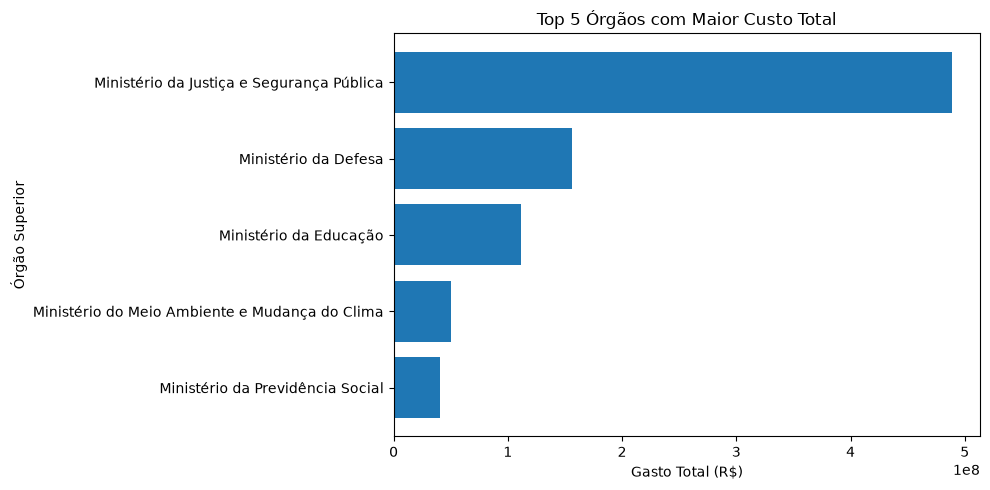


------------------------------------------------------------



In [11]:
print("=" * 60)
print(" TOP 5 Órgãos com Maior Custo Total")
print("=" * 60 + "\n")

sql_p1 = """
SELECT 
    nome_orgao_superior,
    ROUND(SUM(valor_diarias + valor_passagens + valor_outros_gastos), 2) AS gasto_total,
    COUNT(*) AS quantidade_viagens
FROM silver_2025_viagem
WHERE nome_orgao_superior IS NOT NULL
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5
"""
df_p1 = consultar(sql_p1)
if df_p1 is not None and not df_p1.empty:
    print(" TOP 5 Órgãos com Maior Custo Total:")
    df_p1['gasto_total_fmt'] = df_p1['gasto_total'].apply(reais)
    print(df_p1[['nome_orgao_superior', 'quantidade_viagens', 'gasto_total_fmt']].to_string(index=False))
    
    plt.figure(figsize=(10, 5))
    plt.barh(df_p1['nome_orgao_superior'], df_p1['gasto_total'], color='#1f77b4')
    plt.xlabel('Gasto Total (R$)')
    plt.ylabel('Órgão Superior')
    plt.title('Top 5 Órgãos com Maior Custo Total')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print("\n" + "-"*60 + "\n")

TOP 3 Destinos com Maior Custo Médio por Viagem

TOP 3 Destinos com Maior Custo Médio por Viagem:
                                          destinos  total_viagens custo_medio_fmt
  Brasília/DF, Manaus/AM, Brasília/DF, Brasília/DF              2   R$ 127.891,06
Brasília/DF, São Luís/MA, Brasília/DF, Brasília/DF              2   R$ 127.569,66
 Brasília/DF, Goiânia/GO, Brasília/DF, Brasília/DF              2   R$ 127.273,13


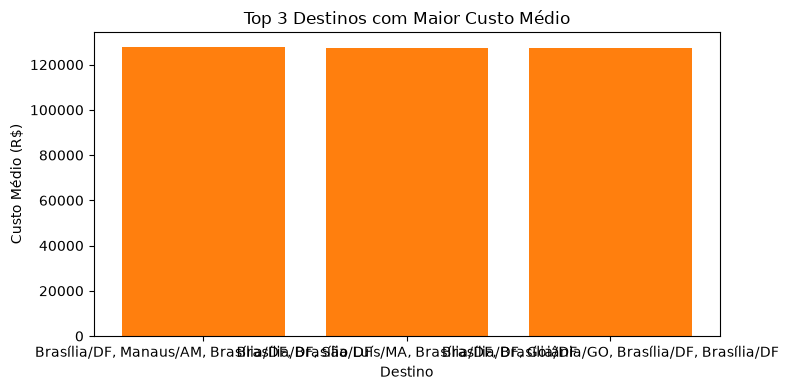


------------------------------------------------------------



In [12]:
print("=" * 60)
print("TOP 3 Destinos com Maior Custo Médio por Viagem")
print("=" * 60 + "\n")

sql_p2 = """
SELECT 
    destinos,
    COUNT(*) AS total_viagens,
    ROUND(AVG(valor_diarias + valor_passagens + valor_outros_gastos), 2) AS custo_medio
FROM silver_2025_viagem
WHERE destinos IS NOT NULL AND destinos <> ''
GROUP BY destinos
HAVING COUNT(*) >= 2
ORDER BY custo_medio DESC
LIMIT 3
"""
df_p2 = consultar(sql_p2)
if df_p2 is not None and not df_p2.empty:
    print("TOP 3 Destinos com Maior Custo Médio por Viagem:")
    df_p2['custo_medio_fmt'] = df_p2['custo_medio'].apply(reais)
    print(df_p2[['destinos', 'total_viagens', 'custo_medio_fmt']].to_string(index=False))
    
    plt.figure(figsize=(8, 4))
    plt.bar(df_p2['destinos'], df_p2['custo_medio'], color='#ff7f0e')
    plt.ylabel('Custo Médio (R$)')
    plt.xlabel('Destino')
    plt.title('Top 3 Destinos com Maior Custo Médio')
    plt.tight_layout()
    plt.show()
    print("\n" + "-"*60 + "\n")
else:
    print("❌ Nenhum dado retornado.")

In [52]:
print("=" * 60)
print(" Viagem de Maior Duração e Custo Total")
print("=" * 60 + "\n")

sql_p3 = """
SELECT 
    identificador_processo_viagem,
    nome,
    cargo,
    nome_orgao_superior,
    (periodo_data_fim - periodo_data_inicio) AS duracao_dias,
    ROUND((valor_diarias + valor_passagens + valor_outros_gastos), 2) AS gasto_total
FROM silver_2025_viagem
WHERE periodo_data_fim IS NOT NULL AND periodo_data_inicio IS NOT NULL
ORDER BY duracao_dias DESC, gasto_total DESC
LIMIT 1
"""
df_p3 = consultar(sql_p3)
if df_p3 is not None and not df_p3.empty:
    v = df_p3.iloc[0]
    print("Viagem de Maior Duração:")
    print(f"   • Processo ID: {v['identificador_processo_viagem']}")
    print(f"   • Viajante: {v['nome']} ({v['cargo']})")
    print(f"   • Órgão: {v['nome_orgao_superior']}")
    print(f"   • Duração: {v['duracao_dias']} dias")
    print(f"   • Custo Total: {reais(v['gasto_total'])}")
    print("\n" + "-"*60 + "\n")
else:
    print("❌ Nenhum dado retornado.")

 Viagem de Maior Duração e Custo Total

Viagem de Maior Duração:
   • Processo ID: 0000000000020699856
   • Viajante: LUISANGELA CORREA FRANCO DE FARIA (TECNICO DO SEGURO SOCIAL)
   • Órgão: Ministério da Previdência Social
   • Duração: 383 dias
   • Custo Total: R$ 0,00

------------------------------------------------------------



In [54]:
print("=" * 60)
print(" Tipo de Pagamento com Maior Valor Médio ")
print("=" * 60 + "\n")

sql_p4 = """
SELECT 
    tipo_pagamento,
    COUNT(*) AS qtd_pagamentos,
    ROUND(AVG(valor), 2) AS valor_medio
FROM silver_2025_pagamento
WHERE tipo_pagamento IS NOT NULL AND tipo_pagamento <> ''
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC
LIMIT 1
"""
df_p4 = consultar(sql_p4)
if df_p4 is not None and not df_p4.empty:
    p = df_p4.iloc[0]
    print(" Tipo de Pagamento com Maior Valor Médio:")
    print(f"   • Tipo: {p['tipo_pagamento']}")
    print(f"   • Valor Médio: {reais(p['valor_medio'])}")
    print(f"   • Quantidade de Registros: {p['qtd_pagamentos']:,}")
    print("\n" + "-"*60 + "\n")
else:
    print("❌ Nenhum dado retornado.")

 Tipo de Pagamento com Maior Valor Médio 

 Tipo de Pagamento com Maior Valor Médio:
   • Tipo: DIÁRIAS
   • Valor Médio: R$ 2.078,28
   • Quantidade de Registros: 401,463

------------------------------------------------------------



In [59]:
print("=" * 60)
print(" Meio de Transporte Mais Usado nos Trechos")
print("=" * 60 + "\n")

sql_p5 = """
SELECT 
    meio_transporte,
    COUNT(*) AS total_usos
FROM silver_2025_trecho
WHERE meio_transporte IS NOT NULL AND meio_transporte <> ''
GROUP BY meio_transporte
ORDER BY total_usos DESC
LIMIT 1
"""

df_p5 = consultar(sql_p5)

if df_p5 is not None and not df_p5.empty:
    t = df_p5.iloc[0]
    print(" Meio de Transporte Mais Usado nos Trechos:")
    print(f"   • Meio de Transporte: {t['meio_transporte']}")
    print(f"   • Total de Utilizações: {t['total_usos']:,}")
    print("\n" + "-"*60 + "\n")
else:
    print("❌ Nenhum dado retornado.")

 Meio de Transporte Mais Usado nos Trechos

 Meio de Transporte Mais Usado nos Trechos:
   • Meio de Transporte: Veículo Oficial
   • Total de Utilizações: 386,424

------------------------------------------------------------



In [57]:
print("=" * 60)
print(" UF de Destino com Mais Trechos")
print("=" * 60 + "\n")


sql_p6 = """
SELECT 
    destino_uf,
    COUNT(*) AS total_trechos
FROM silver_2025_trecho
WHERE destino_uf IS NOT NULL AND destino_uf <> ''
GROUP BY destino_uf
ORDER BY total_trechos DESC
LIMIT 1
"""
df_p6 = consultar(sql_p6)
if df_p6 is not None and not df_p6.empty:
    uf = df_p6.iloc[0]
    print("UF de Destino com Mais Trechos:")
    print(f"   • UF: {uf['destino_uf']}")
    print(f"   • Total de Trechos: {uf['total_trechos']:,}")
    print("\n" + "-"*60 + "\n")

else:
    print("❌ Nenhum dado retornado.")

 UF de Destino com Mais Trechos

UF de Destino com Mais Trechos:
   • UF: São Paulo
   • Total de Trechos: 82,722

------------------------------------------------------------



In [58]:
print("=" * 60)
print(" Órgão que Pagou Mais no Total ")
print("=" * 60 + "\n")


sql_p7 = """
SELECT 
    v.nome_orgao_superior,
    ROUND(SUM(p.valor), 2) AS total_pago
FROM silver_2025_viagem v
JOIN silver_2025_pagamento p ON v.identificador_processo_viagem = p.identificador_processo_viagem
WHERE v.nome_orgao_superior IS NOT NULL
GROUP BY v.nome_orgao_superior
ORDER BY total_pago DESC
LIMIT 1
"""
df_p7 = consultar(sql_p7)
if df_p7 is not None and not df_p7.empty:
    org = df_p7.iloc[0]
    print("Órgão que Pagou Mais no Total:")
    print(f"   • Órgão Superior: {org['nome_orgao_superior']}")
    print(f"   • Valor Total Pago: {reais(org['total_pago'])}")
    print("\n" + "="*60)
else:
    print("❌ Nenhum dado retornado.")

 Órgão que Pagou Mais no Total 

Órgão que Pagou Mais no Total:
   • Órgão Superior: Ministério da Justiça e Segurança Pública
   • Valor Total Pago: R$ 488.831.110,61

